In [4]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/student_mental_health.csv")

X = df.drop(columns=['Mental_Health_Risk', 'Student_ID'])
y = df['Mental_Health_Risk']



In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [6]:
print("Taille du dataset initial :", df.shape)

print("\nTaille de X_train :", X_train.shape)
print("Taille de X_test :", X_test.shape)

print("\nDistribution de y_train :")
print(y_train.value_counts())

print("\nDistribution de y_test :")
print(y_test.value_counts())

Taille du dataset initial : (2000, 17)

Taille de X_train : (1600, 15)
Taille de X_test : (400, 15)

Distribution de y_train :
Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64

Distribution de y_test :
Mental_Health_Risk
High      136
Medium    132
Low       132
Name: count, dtype: int64


In [9]:
missing_values = df.isnull().sum()
print(missing_values)

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


In [10]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Variables numériques :")
print(numerical_columns)

print("\nVariables catégorielles :")
print(categorical_columns)

Variables numériques :
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Variables catégorielles :
['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


C:\Users\Olaya\AppData\Local\Temp\ipykernel_48156\593650070.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [11]:
from sklearn.impute import SimpleImputer

numerical_imputer = SimpleImputer(strategy='median')

df[numerical_columns] = numerical_imputer.fit_transform(
    df[numerical_columns]
)

categorical_imputer = SimpleImputer(strategy='most_frequent')

df[categorical_columns] = categorical_imputer.fit_transform(
    df[categorical_columns]
)

In [12]:
print("Valeurs manquantes après imputation :")

print(df.isnull().sum())

print("\nTotal des valeurs manquantes :")
print(df.isnull().sum().sum())

Valeurs manquantes après imputation :
Student_ID                        0
Age                               0
Gender                            0
Year_of_Study                     0
Sleep_Hours                       0
Study_Hours_Per_Week              0
GPA                               0
Social_Media_Hours                0
Screen_Time_Hours                 0
Physical_Activity                 0
Financial_Stress                  0
Family_Support                    0
Attendance_Rate                   0
Part_Time_Job                     0
Diet_Quality                      0
Previous_Mental_Health_History    0
Mental_Health_Risk                0
dtype: int64

Total des valeurs manquantes :
0


In [ ]:
numerical_columns = [
    'Age',
    'Sleep_Hours',
    'Study_Hours_Per_Week',
    'GPA',
    'Social_Media_Hours',
    'Screen_Time_Hours',
    'Attendance_Rate'
]

numerical_columns = [
    col for col in numerical_columns if col in df.columns
]

print(numerical_columns)

['Age', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Attendance_Rate']


In [14]:
outliers_results = []

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outliers_results.append({
        'Variable': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Nombre Outliers': len(outliers)
    })

outliers_df = pd.DataFrame(outliers_results)

outliers_df

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Nombre Outliers
0,Age,20.00,23.00,3.00,15.50,27.50,4
1,Sleep_Hours,6.00,7.50,1.50,3.75,9.75,12
2,Study_Hours_Per_Week,16.00,24.00,8.00,4.00,36.00,7
3,GPA,2.33,2.79,0.46,1.64,3.48,9
4,Social_Media_Hours,5.30,6.70,1.40,3.20,8.80,25
5,Screen_Time_Hours,7.40,9.70,2.30,3.95,13.15,7
6,Attendance_Rate,80.40,89.80,9.40,66.30,103.90,13


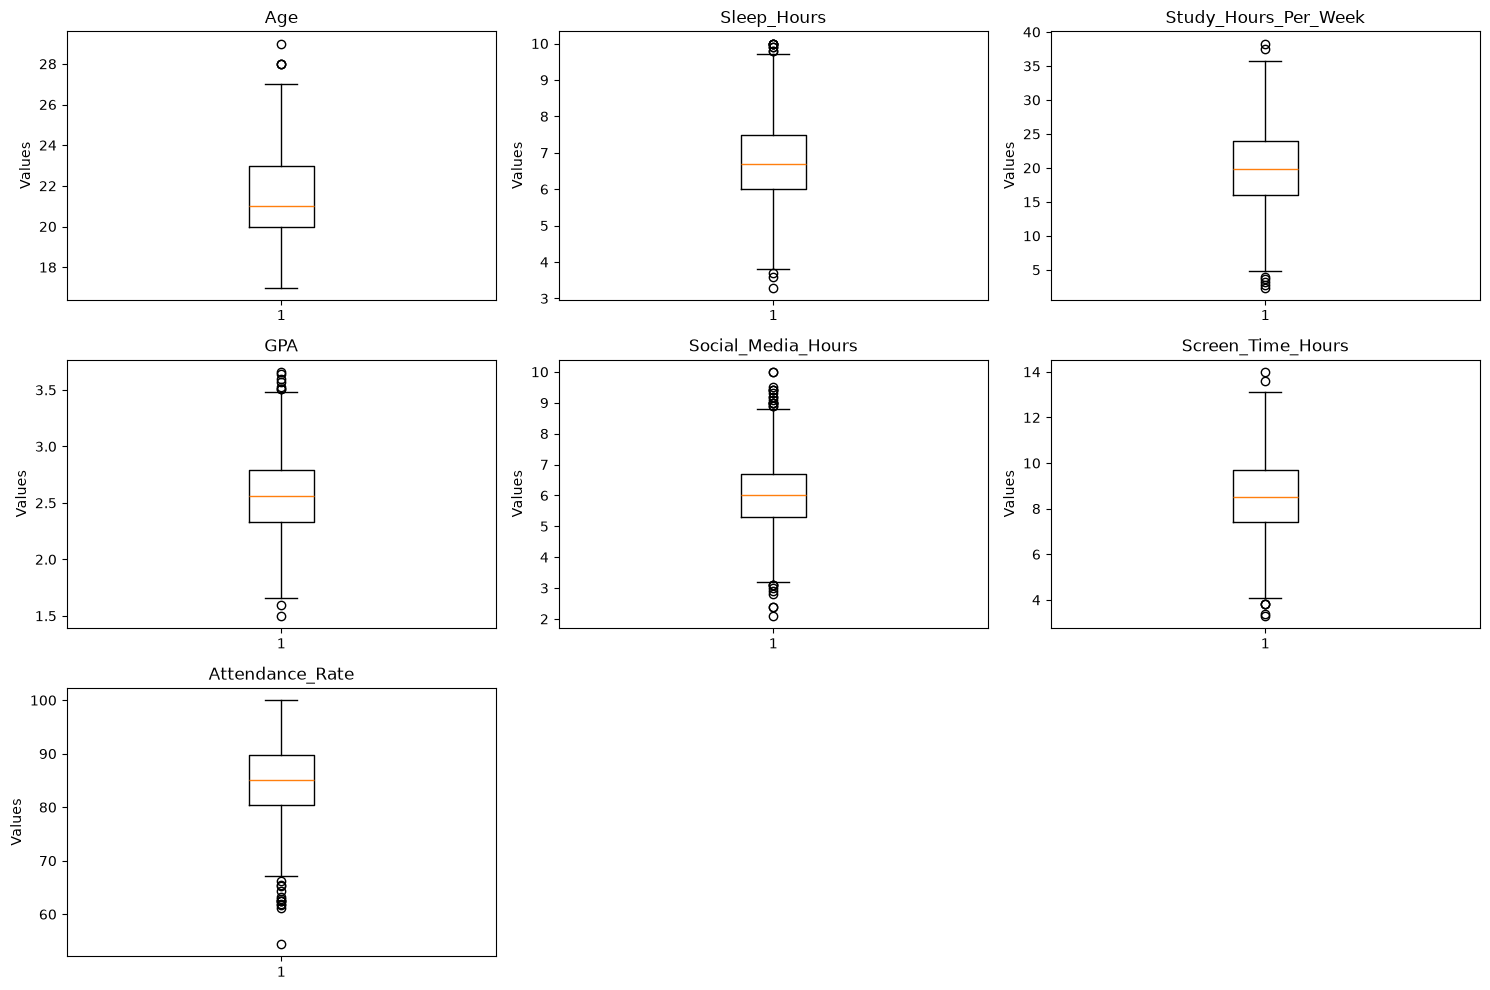

In [15]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_columns, 1):

    plt.subplot(3, 3, i)

    plt.boxplot(df[col].dropna())

    plt.title(col)
    plt.ylabel('Values')

plt.tight_layout()
plt.show()

In [16]:
# Séparer les variables explicatives et la cible
X = df.drop(columns=['Mental_Health_Risk', 'Student_ID'])
y = df['Mental_Health_Risk']

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Calculer les limites IQR sur le Training Set
for col in numerical_columns:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Appliquer le Capping
    X_train[col] = X_train[col].clip(
        lower_bound, upper_bound
    )

    X_test[col] = X_test[col].clip(
        lower_bound, upper_bound
    )

In [17]:
for col in numerical_columns:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    ).sum()

    print(f"{col}: {count} outliers")

Age: 0 outliers
Sleep_Hours: 0 outliers
Study_Hours_Per_Week: 0 outliers
GPA: 0 outliers
Social_Media_Hours: 0 outliers
Screen_Time_Hours: 0 outliers
Attendance_Rate: 0 outliers


Encadage les variables categorielles

In [18]:
categorical_columns = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Variables catégorielles :")
print(categorical_columns)

Variables catégorielles :
['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\Olaya\AppData\Local\Temp\ipykernel_48156\1405079473.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


In [19]:
for col in categorical_columns:

    print(f"\nVariable : {col}")

    print(X_train[col].value_counts(dropna=False))


Variable : Gender
Gender
Female        779
Male          746
Non-binary     75
Name: count, dtype: int64

Variable : Physical_Activity
Physical_Activity
Moderate    742
Low         539
High        319
Name: count, dtype: int64

Variable : Part_Time_Job
Part_Time_Job
No     1029
Yes     571
Name: count, dtype: int64

Variable : Diet_Quality
Diet_Quality
Average    742
Poor       476
Good       382
Name: count, dtype: int64

Variable : Previous_Mental_Health_History
Previous_Mental_Health_History
No     1140
Yes     460
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Créer l'encodeur
encoder = OneHotEncoder(
    handle_unknown='ignore',
    drop='first',
    sparse_output=False
)

# Apprendre sur Train et encoder
X_train_encoded = encoder.fit_transform(
    X_train[categorical_columns]
)

# Encoder Test avec les mêmes catégories
X_test_encoded = encoder.transform(
    X_test[categorical_columns]
)

# Récupérer les noms des nouvelles colonnes
encoded_columns = encoder.get_feature_names_out(
    categorical_columns
)

# Convertir en DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

In [21]:
# Supprimer les anciennes colonnes catégorielles
X_train_final = X_train.drop(
    columns=categorical_columns
)

X_test_final = X_test.drop(
    columns=categorical_columns
)

# Ajouter les colonnes encodées
X_train_final = pd.concat(
    [X_train_final, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_final, X_test_encoded],
    axis=1
)

In [22]:
print("Training Set :", X_train_final.shape)
print("Testing Set :", X_test_final.shape)

print("\nColonnes catégorielles restantes :")

print(
    X_train_final.select_dtypes(
        include=['object', 'category']
    ).columns.tolist()
)

print("\nAperçu des données :")

display(X_train_final.head())

Training Set : (1600, 18)
Testing Set : (400, 18)

Colonnes catégorielles restantes :
[]

Aperçu des données :


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate,Gender_Male,Gender_Non-binary,Physical_Activity_Low,Physical_Activity_Moderate,Part_Time_Job_Yes,Diet_Quality_Good,Diet_Quality_Poor,Previous_Mental_Health_History_Yes
726,21.0,2.0,5.2,18.6,2.59,6.2,10.4,7.3,7.7,76.1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1384,23.0,1.0,4.9,12.3,2.23,6.4,8.9,4.4,7.2,81.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1579,19.0,2.0,7.2,17.0,2.21,5.7,7.2,5.4,7.9,90.6,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1098,23.0,1.0,8.3,19.5,2.87,6.9,10.4,7.5,4.8,83.5,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
582,22.0,3.0,7.2,23.8,2.47,5.6,8.0,7.2,7.8,74.6,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


 standardiser les variables numériques

In [23]:
numerical_features = [
    'Age',
    'Sleep_Hours',
    'Study_Hours_Per_Week',
    'GPA',
    'Social_Media_Hours',
    'Screen_Time_Hours',
    'Attendance_Rate'
]

# Garder uniquement les colonnes présentes
numerical_features = [
    col for col in numerical_features
    if col in X_train_final.columns
]

print("Variables à standardiser :")
print(numerical_features)

Variables à standardiser :
['Age', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Attendance_Rate']


In [24]:
from sklearn.preprocessing import StandardScaler

# Créer le scaler
scaler = StandardScaler()

# Apprendre et transformer les données Train
X_train_final[numerical_features] = scaler.fit_transform(
    X_train_final[numerical_features]
)

# Transformer les données Test avec les mêmes paramètres
X_test_final[numerical_features] = scaler.transform(
    X_test_final[numerical_features]
)

In [25]:
print("Moyenne après standardisation :")

print(X_train_final[numerical_features].mean())

print("\nÉcart-type après standardisation :")

print(X_train_final[numerical_features].std())

Moyenne après standardisation :
Age                    -7.260859e-16
Sleep_Hours             1.643130e-16
Study_Hours_Per_Week    2.109424e-16
GPA                     8.215650e-16
Social_Media_Hours      2.531308e-16
Screen_Time_Hours      -4.363176e-16
Attendance_Rate         9.725554e-16
dtype: float64

Écart-type après standardisation :
Age                     1.000313
Sleep_Hours             1.000313
Study_Hours_Per_Week    1.000313
GPA                     1.000313
Social_Media_Hours      1.000313
Screen_Time_Hours       1.000313
Attendance_Rate         1.000313
dtype: float64


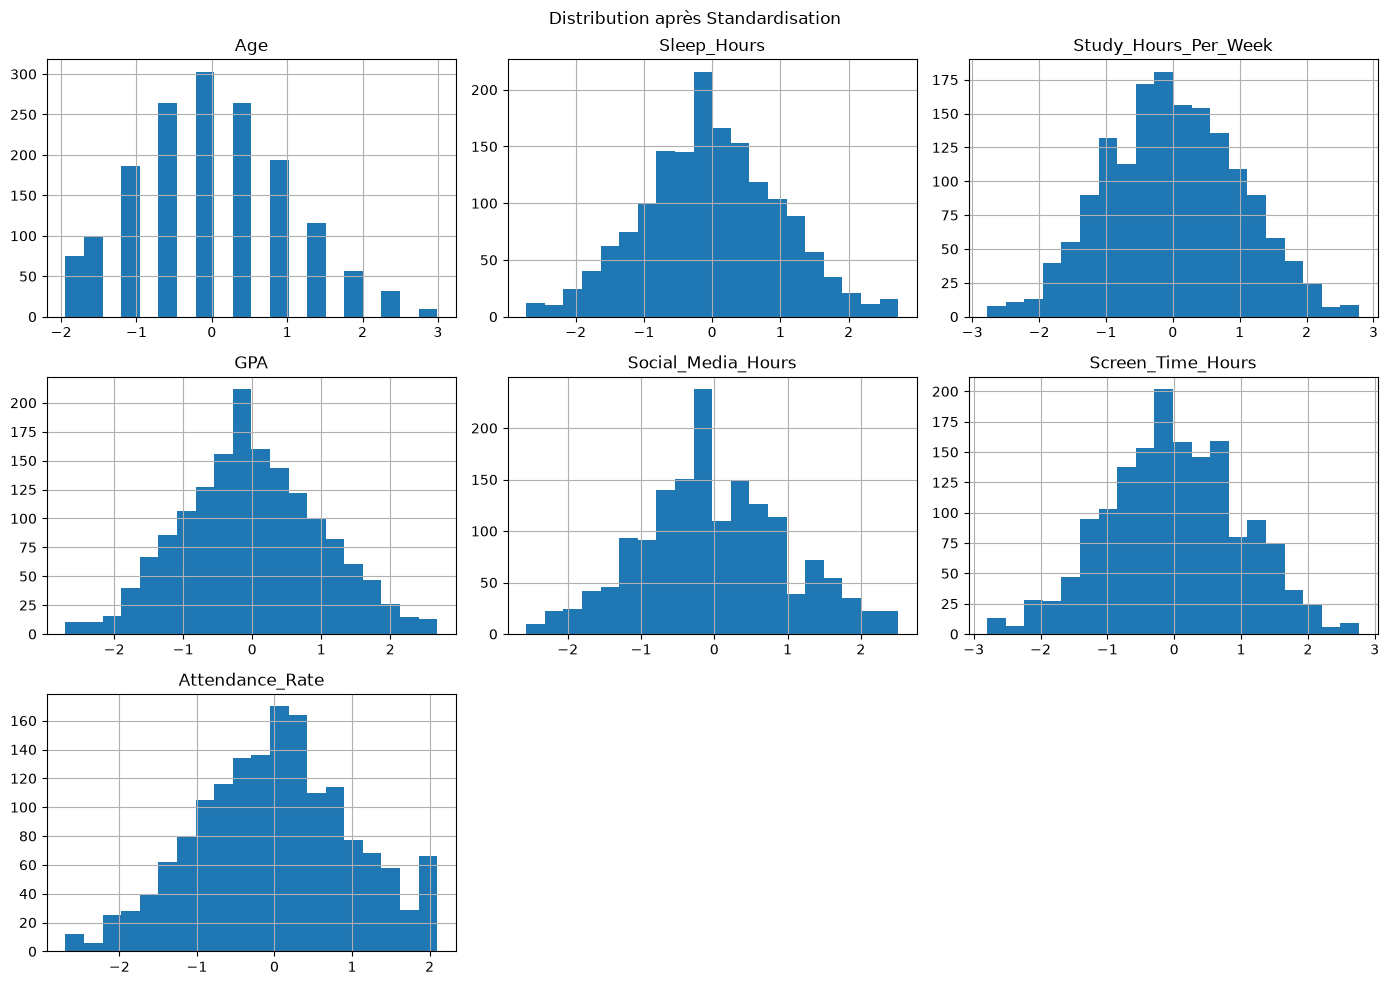

In [26]:
X_train_final[numerical_features].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution après Standardisation")
plt.tight_layout()
plt.show()
